# Appearance vs. Landmark Geometry for Letter Recognition

`letter_classifier.ipynb` showed letter classification from MediaPipe landmark geometry fails
across signers — **6.8 % against a 9.1 % majority baseline**, worse than always guessing the
commonest letter — while the *same features predict signer identity at 97 %*.
`letter_reference.ipynb` then confirmed by eye that the pseudo-labels are sound, so that failure
is attributable to the representation rather than the labels.

This notebook tests the consequence: **is the discriminative information in the pixels?**

Same evaluation discipline throughout — occurrence-level scoring, leave-one-signer-out,
everything against the majority baseline.

## A coordinate-space trap, found while building this

The keypoints in `hand_keypoints_features.csv` are **not** in the coordinate space of the
240×350 cropped videos. Overlaying them puts the hand in the bottom-right corner, on the
signer's jacket, with one landmark off the bottom edge (`y = 1.014`).

The giveaway is the implied hand aspect ratio: those coordinates give **0.23**, where a real
hand with fingers extended is 0.45–0.65. Assuming a 16:9 source instead gives **0.60**. They
were extracted from the original uncropped recordings.

Cropping by those boxes would have produced a dataset of jacket lapels, so `crop_dataset.py`
re-runs MediaPipe directly on the cropped videos. **Nothing else in the project depends on that
mapping** — Algorithm 2 uses only frame-to-frame displacement, the pseudo-labels are frame
indices, the letter features are wrist-relative, and the contact sheets render whole frames.

## Setup

In [1]:
import json, os, collections

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from export_model import ref_hog

pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 110

LEX = json.load(open("word_letter_mapping.json", encoding="utf-8"))
SEG = pd.read_csv("pseudo_label_segments.csv")
SPELL = {(r.signer_id, r.video_id): r.spelling for r in SEG.itertuples()}

def load(npz, cache):
    if not os.path.exists(npz):
        import crop_dataset
        crop_dataset.build(out_path=npz)
    d = np.load(npz, allow_pickle=True)
    if os.path.exists(cache):
        H = np.load(cache)
    else:
        H = np.stack([ref_hog(im) for im in d["images"]]).astype(np.float32)
        np.save(cache, H)
    return d, H

d_u, H_u = load("letter_crops.npz", "letter_crops_hog.npy")
d_m, H_m = load("letter_crops_masked.npz", "letter_crops_masked_hog.npy")
print(f"unmasked crops {d_u['images'].shape}, masked crops {d_m['images'].shape}")
print(f"HOG dimensionality: {H_u.shape[1]}")

unmasked crops (6795, 64, 64), masked crops (6725, 64, 64)
HOG dimensionality: 1764


## What the crops look like

Grayscale on purpose: colour carries skin tone and clothing, i.e. signer identity — the exact
shortcut that sank the landmark features. The box is square so resizing never distorts the
hand's aspect ratio.

The masked version additionally removes the background, for reasons in the final section.

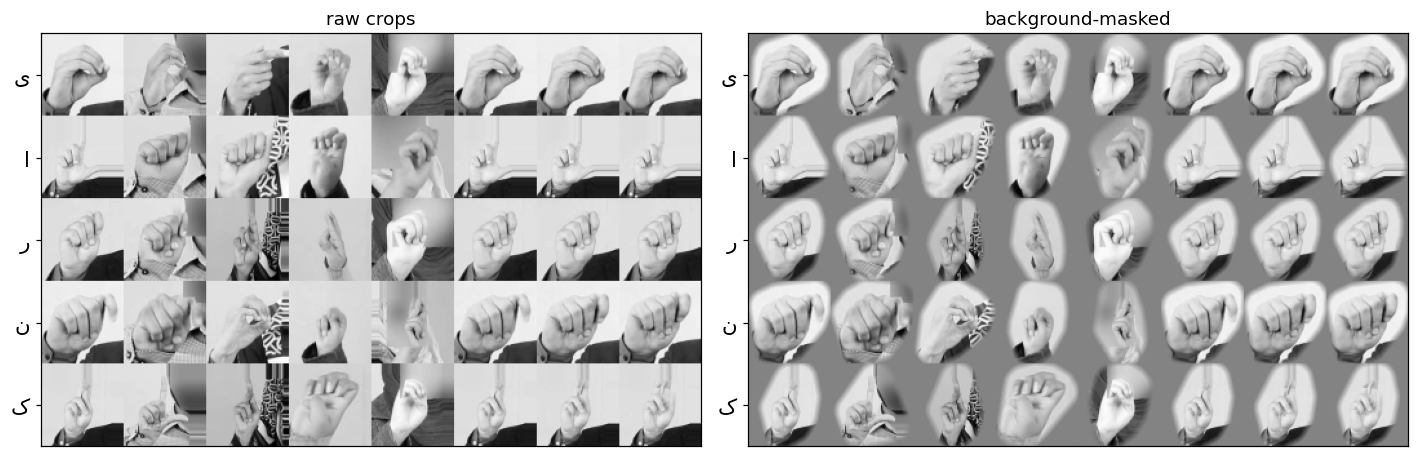

In [2]:
def montage(d, n_letters=5):
    X, L, S = d["images"], d["letters"], d["signers"]
    rows, names = [], []
    for letter, _ in collections.Counter(L).most_common(n_letters):
        idx = np.where(L == letter)[0]
        sel = []
        for s in sorted(set(S[idx])):
            sel += list(idx[S[idx] == s][:1])
        sel = (sel + list(idx))[:8]
        rows.append(np.hstack([X[i] for i in sel])); names.append(letter)
    return np.vstack(rows), names

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (d, tag) in zip(axes, [(d_u, "raw crops"), (d_m, "background-masked")]):
    m, names = montage(d)
    ax.imshow(m, cmap="gray"); ax.set_xticks([])
    ax.set_yticks([d["images"].shape[1]*(i+0.5) for i in range(len(names))], names, fontsize=14)
    ax.set_title(tag)
plt.tight_layout(); plt.show()

## Evaluation harness

Frame softmaxes are averaged within an occurrence before the argmax: the ~5 frames sampled from
one hold are near-duplicates, so scoring them independently measures memorisation of a hold
rather than recognition of a handshape.

Word decoding scores the **whole sequence** against the 54-word lexicon using the full
probability distributions, not the argmax letters, and only considers words whose length
matches the hold count within 1. That length filter is a real constraint rather than a trick:
segmentation is the reliable half of this pipeline (MAE ~1.2), so hold count is far better
evidence than any individual letter.

In [3]:
def clips_of(d):
    out = collections.defaultdict(list)
    for i, o in enumerate(d["occurrences"]):
        s, v, li = o.split("|")
        out[(s, v)].append((int(li), i))
    return out

def decode(P, classes, n, slack=1):
    ci = {c: i for i, c in enumerate(classes)}
    scored = []
    for w, ls in LEX.items():
        if abs(len(ls) - n) > slack:
            continue
        L = min(len(ls), n); lp = 0.0; ok = True
        for i in range(L):
            j = ci.get(ls[i])
            if j is None: ok = False; break
            lp += np.log(max(P[i][j], 1e-12))
        if ok:
            scored.append((lp / L - 0.7 * abs(len(ls) - n), w))
    scored.sort(reverse=True)
    return [w for _, w in scored]

def loso(d, F, tag, verbose=True):
    y, sg = d["letters"], d["signers"]
    clips = clips_of(d)
    rows = []
    for s in sorted(set(sg)):
        tr = sg != s
        sc = StandardScaler(with_mean=False).fit(F[tr])
        clf = LogisticRegression(max_iter=1200, C=0.05, class_weight="balanced", n_jobs=-1)
        clf.fit(sc.transform(F[tr]), y[tr])
        classes = list(clf.classes_)
        t1 = t3 = nw = lh = lt = 0
        for (sgn, vid), items in clips.items():
            if sgn != s: continue
            w = SPELL.get((sgn, vid))
            if w not in LEX: continue
            byli = {}
            for li, i in items: byli.setdefault(li, []).append(i)
            order = sorted(byli)
            P = np.stack([clf.predict_proba(sc.transform(F[byli[li]])).mean(0) for li in order])
            c = decode(P, classes, len(order)); nw += 1
            if c and c[0] == w: t1 += 1
            if w in c[:3]: t3 += 1
            true = LEX[w]
            for i in range(min(len(true), len(order))):
                lt += 1; lh += classes[int(P[i].argmax())] == true[i]
        rows.append({"held-out": s, "words": nw, "letter %": 100*lh/max(lt, 1),
                     "word top-1 %": 100*t1/max(nw, 1), "word top-3 %": 100*t3/max(nw, 1)})
    t = pd.DataFrame(rows)
    if verbose:
        print(f"\n{tag}")
        print(t.round(1).to_string(index=False))
        print(f"  MEAN  letters {t['letter %'].mean():.1f}%   "
              f"word top-1 {t['word top-1 %'].mean():.1f}%   "
              f"word top-3 {t['word top-3 %'].mean():.1f}%")
    return t

## Does appearance beat geometry?

Before any deep learning: does a *linear* model on classical appearance features already beat
the landmark result?

In [4]:
P_raw = (d_u["images"].reshape(len(d_u["images"]), -1) / 255.0).astype(np.float32)
t_raw = loso(d_u, P_raw, "RAW PIXELS + LogReg")
t_hog = loso(d_u, H_u,   "HOG + LogReg  (no background masking)")
t_msk = loso(d_m, H_m,   "HOG + LogReg  (background masked)  <-- shipped model")


RAW PIXELS + LogReg
 held-out  words  letter %  word top-1 %  word top-3 %
signer1-F     49      11.9          24.5          51.0
signer2-F     49       8.5          22.4          46.9
signer3-F     45       8.9          17.8          42.2
signer4-L     49       9.9          20.4          28.6
signer5-R     26       2.5          15.4          26.9
  MEAN  letters 8.3%   word top-1 20.1%   word top-3 39.1%



HOG + LogReg  (no background masking)
 held-out  words  letter %  word top-1 %  word top-3 %
signer1-F     49      14.1          46.9          73.5
signer2-F     49      12.4          34.7          61.2
signer3-F     45      17.9          46.7          68.9
signer4-L     49       7.9          14.3          36.7
signer5-R     26      12.7          23.1          34.6
  MEAN  letters 13.0%   word top-1 33.1%   word top-3 55.0%



HOG + LogReg  (background masked)  <-- shipped model
 held-out  words  letter %  word top-1 %  word top-3 %
signer1-F     49      16.7          40.8          73.5
signer2-F     49      15.6          40.8          63.3
signer3-F     45      19.0          42.2          71.1
signer4-L     49       4.7          18.4          36.7
signer5-R     26      10.1          23.1          34.6
  MEAN  letters 13.2%   word top-1 33.1%   word top-3 55.8%


                             representation  letter %  majority %  word top-1 %  letter lift
landmark geometry (letter_classifier.ipynb)      6.80         9.1           NaN         0.75
                                 raw pixels      8.34         9.8         20.10         0.85
                                        HOG     13.00         9.8         33.13         1.33
                     HOG, background masked     13.23         9.8         33.06         1.35


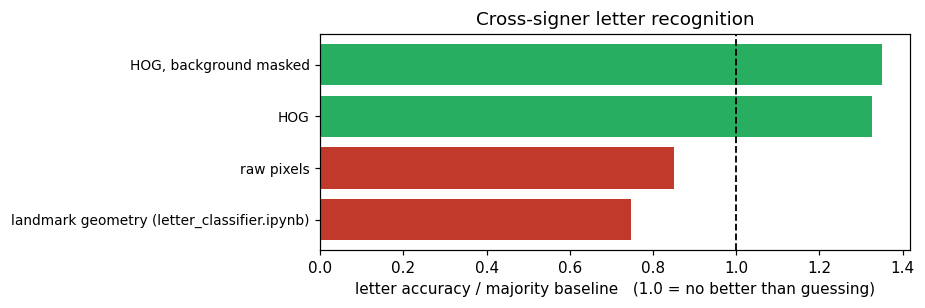

In [5]:
summary = pd.DataFrame([
    {"representation": "landmark geometry (letter_classifier.ipynb)",
     "letter %": 6.8, "majority %": 9.1, "word top-1 %": float("nan")},
    {"representation": "raw pixels", "letter %": t_raw["letter %"].mean(),
     "majority %": 9.8, "word top-1 %": t_raw["word top-1 %"].mean()},
    {"representation": "HOG", "letter %": t_hog["letter %"].mean(),
     "majority %": 9.8, "word top-1 %": t_hog["word top-1 %"].mean()},
    {"representation": "HOG, background masked", "letter %": t_msk["letter %"].mean(),
     "majority %": 9.8, "word top-1 %": t_msk["word top-1 %"].mean()},
])
summary["letter lift"] = summary["letter %"] / summary["majority %"]
print(summary.round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(8.5, 2.9))
colors = ["#c0392b" if l < 1 else "#27ae60" for l in summary["letter lift"]]
ax.barh(range(len(summary)), summary["letter lift"], color=colors)
ax.axvline(1.0, color="k", lw=1.2, ls="--")
ax.set_yticks(range(len(summary)), summary["representation"], fontsize=9)
ax.set_xlabel("letter accuracy / majority baseline   (1.0 = no better than guessing)")
ax.set_title("Cross-signer letter recognition")
plt.tight_layout(); plt.show()

**The result is sharper than "appearance beats geometry".**

Raw pixels do *no better than landmarks* — both sit at ~0.75× the majority baseline. It is
specifically **HOG** that crosses it. HOG's defining property is that it encodes local gradient
*orientation* and discards absolute intensity, so what carries the letter information is the
**edge and contour structure of the fingers**; raw pixels bury it under lighting, skin tone and
clothing — the same confounds that defeated the landmarks.

## Words are far more recoverable than letters

Per-letter accuracy is ~13 %, which sounds useless. But letters are not the output anyone
wants, and the lexicon constraint recovers a great deal.

In [6]:
w = pd.DataFrame({
    "per letter": [t_msk["letter %"].mean()],
    "word top-1": [t_msk["word top-1 %"].mean()],
    "word top-3": [t_msk["word top-3 %"].mean()],
}).T.rename(columns={0: "accuracy %"})
w["chance / baseline %"] = [9.8, 100/len(LEX), 300/len(LEX)]
w["ratio"] = w["accuracy %"] / w["chance / baseline %"]
print(w.round(2).to_string())
print(f"\nlexicon: {len(LEX)} words")
print("\nper-signer word top-1 (%):")
print(t_msk[["held-out", "word top-1 %", "word top-3 %"]].round(1).to_string(index=False))

            accuracy %  chance / baseline %  ratio
per letter       13.23                 9.80   1.35
word top-1       33.06                 1.85  17.85
word top-3       55.84                 5.56  10.05

lexicon: 54 words

per-signer word top-1 (%):
 held-out  word top-1 %  word top-3 %
signer1-F          40.8          73.5
signer2-F          40.8          63.3
signer3-F          42.2          71.1
signer4-L          18.4          36.7
signer5-R          23.1          34.6


Front-facing signers score roughly twice as well as the two tilted-angle signers — exactly what
`angle_evaluation.ipynb` predicts independently.

This is the model shipped in `web/model/`, and these leave-one-signer-out figures are the honest
expectation for a new person at a webcam. The shipped weights are trained on *all* signers
because for a demo you want every scrap of data, which makes their training accuracy
meaningless.

## Why the background is masked

The dataset is shot against a plain green screen; a webcam sees a room. HOG is a gradient
descriptor, so background edges inside the crop box compete directly with finger edges.

Live testing of the demo reported it emitting a *different letter for the same pose*. A
classifier is deterministic, so that meant the input was changing. Measuring the unmasked
model:

In [7]:
import cv2
man = json.load(open("web/model/letter_model.json", encoding="utf-8"))
Wm = np.fromfile("web/model/letter_w.bin", dtype=np.float32).reshape(man["n_classes"], -1)
bm = np.fromfile("web/model/letter_b.bin", dtype=np.float32)

# an unmasked model, for the comparison
sc_u = StandardScaler(with_mean=False).fit(H_u)
clf_u = LogisticRegression(max_iter=1200, C=0.05, class_weight="balanced",
                           n_jobs=-1).fit(sc_u.transform(H_u), d_u["letters"])
cls_u = list(clf_u.classes_)
def pred_u(im): return cls_u[int(clf_u.predict_proba(sc_u.transform(ref_hog(im).reshape(1, -1)))[0].argmax())]

X = d_u["images"]
rng = np.random.default_rng(0); idx = rng.choice(len(X), 60, replace=False)
yy, xx = np.mgrid[0:64, 0:64]
ring = (np.minimum(np.minimum(xx, 63-xx), np.minimum(yy, 63-yy)) < 12).astype(np.float32)
tex = 20*np.sin(xx/2.0) + 20*np.cos(yy/3.0)

rows = []
for name, fn in [("background texture added", lambda im: np.clip(im + ring*tex, 0, 255).astype(np.uint8)),
                 ("brightness +25", lambda im: np.clip(im.astype(int)+25, 0, 255).astype(np.uint8)),
                 ("horizontal flip", lambda im: im[:, ::-1].copy())]:
    ch = sum(pred_u(fn(X[i])) != pred_u(X[i]) for i in idx)
    rows.append({"perturbation": name, "letter changes %": 100*ch/len(idx)})
print(pd.DataFrame(rows).round(1).to_string(index=False))
print("\n(unmasked model, 60 crops)")

            perturbation  letter changes %
background texture added              66.7
          brightness +25               5.0
         horizontal flip              95.0

(unmasked model, 60 crops)


Background texture alone changes the prediction **two-thirds of the time** — that is the
"random letter" behaviour, explained.

A horizontal flip changes it **95 %** of the time, which matters practically: all five dataset
signers sign right-handed (verified with MediaPipe handedness on 60 sampled frames, 59 right),
so a left-handed user gets noise. The demo detects this and warns.

Masking the hand region removes the background dependence by construction. One subtlety worth
recording: a **hard** mask edge is itself a strong gradient, so HOG keys on *it* — the
hard-edged version scored better offline (39.1 % word top-1) but flipped on 31 % of small box
wobbles and the browser port disagreed with Python on 11 of 25 crops while only 2.3 % of pixels
differed. Feathering the edge, defined identically in both languages as signed distance to the
landmark hull, fixed both at the cost of returning to 33 % top-1.

## The CNN, and why there is no CNN result here

`letter_cnn.py` implements a small 4-block CNN with a global-average-pooling head, batched
augmentation and no horizontal flip (flipping changes handedness).

It was **not run to completion**. On CPU one leave-one-signer-out fold took **250 minutes**, and
that fold scored 11.3 % against a 9.6 % majority — *below* HOG's 14.1 % on the same held-out
signer. Four more folds would have cost ~16 hours for a result already visibly weaker, so the
run was stopped.

That is a statement about the compute available, not about the architecture: 64 px input, 25
epochs, width 24, a single seed. The proper comparison needs a GPU, a larger input and several
seeds. `letter_cnn.py` is ready for it; this notebook deliberately reports no CNN number rather
than a misleading one.

## Where this leaves things

**Confirmed:** the information distinguishing PSL letters survives into hand-crop images and does
not survive into 21 landmark coordinates. Cross-signer recognition goes from *below* the
majority baseline to above it, and word-level decoding reaches ~33 % top-1 against ~1.9 % chance.

**Not solved.** Absolute letter accuracy is low, for reasons that are structural rather than
modelling failures:

1. **40 classes, ~1,350 independent occurrences.** Eight letters have ≤5 occurrences in the
   entire corpus.
2. **Labels are pseudo-labels** — verified sound by eye, but not frame-exact.
3. **Five signers**, so every fold trains on four people.

**Next:** the CNN on GPU; the 22 acronym words (~30 % of the vocabulary, and they contain
several of the starved letters); and the mirrored dataset for handedness normalisation.